In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

portfolio_returns = pd.read_csv("C:\\Users\\henry\\OneDrive\\Documents\\GitHub\\Cyclops\\data\\portfolio_returns.csv")
returns_m = pd.read_csv("C:\\Users\\henry\\OneDrive\\Documents\\GitHub\\Cyclops\\data\\returns_m.csv", index_col=0, parse_dates=True)

In [10]:
K_map = {"1 Month": 1, "3 Months": 3, "6 Months": 6, "12 Months": 12}   # match your column names
pr = portfolio_returns[list(K_map)].dropna()                           # common sample

def perf(r):
    r = r.dropna()
    T = len(r)
    cum = (1 + r).cumprod()
    dd = cum / cum.cummax() - 1
    ann_ret_geo = cum.iloc[-1] ** (12 / T) - 1
    ann_ret_ari = r.mean() * 12
    ann_vol = r.std() * np.sqrt(12)
    downside = r[r < 0].std() * np.sqrt(12)
    sharpe = ann_ret_ari / ann_vol
    return {
        "N": T,
        "ann_return (arith)": ann_ret_ari,
        "ann_return (geo)": ann_ret_geo,
        "ann_vol": ann_vol,
        "sharpe": sharpe,
        "sharpe_se": np.sqrt((1 + 0.5 * (r.mean() / r.std()) ** 2) / T) * np.sqrt(12),
        "sortino": ann_ret_ari / downside,
        "max_drawdown": dd.min(),
        "calmar": ann_ret_geo / abs(dd.min()),
        "hit_rate": (r > 0).mean(),
        "best_month": r.max(),
        "worst_month": r.min(),
        "skew": r.skew()
    }

table = pd.DataFrame({name: perf(pr[name]) for name in K_map}).T
print(table.round(3))

               N  ann_return (arith)  ann_return (geo)  ann_vol  sharpe  \
1 Month    178.0               0.238             0.057    0.611   0.390   
3 Months   178.0               0.207             0.044    0.580   0.358   
6 Months   178.0               0.158             0.023    0.533   0.296   
12 Months  178.0               0.003            -0.067    0.382   0.008   

           sharpe_se  sortino  max_drawdown  calmar  hit_rate  best_month  \
1 Month         0.26    0.671        -0.904   0.063     0.551       0.771   
3 Months        0.26    0.602        -0.812   0.054     0.556       0.795   
6 Months        0.26    0.518        -0.730   0.031     0.528       0.687   
12 Months       0.26    0.014        -0.784  -0.085     0.472       0.385   

           worst_month   skew  
1 Month         -0.501  0.540  
3 Months        -0.493  0.622  
6 Months        -0.411  0.808  
12 Months       -0.299  0.337  


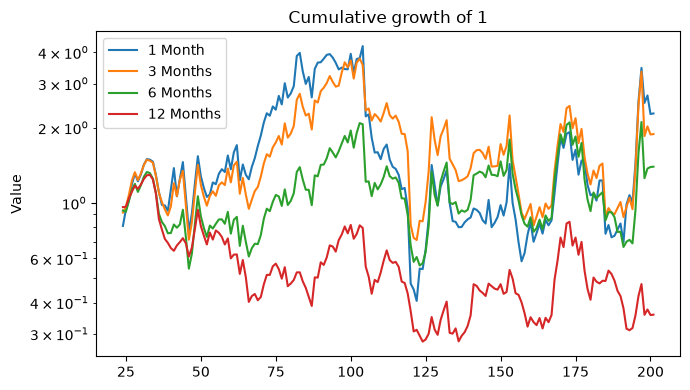

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))

for name in K_map:
    cum = (1 + pr[name]).cumprod()
    ax.plot(cum.index, cum, label=name)

ax.set(title="Cumulative growth of 1", ylabel="Value", yscale="log")
ax.legend()
plt.tight_layout()
plt.show()